<a href="https://colab.research.google.com/github/andre02luiss-rgb/newApp/blob/main/24_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# pandas lê as tabelas; numpy ajuda a criar a coluna de resposta.
import pandas as pd
import numpy as np

print("Pronto! Agora vá até a sua base.")

Pronto! Agora vá até a sua base.


---
## 11 · Banco digital: o cliente vai pagar o empréstimo?

**Tema:** Finanças / crédito · **Nível:** Médio · **Origem:** Traduzida para PT · **Tipo:** Tabela

**A pergunta:** Com idade, salário, valor e juros do empréstimo, o modelo prevê quem vai ficar inadimplente?

| | |
|---|---|
| **Pistas (X)** | `idade_pessoa`, `salario_ano_pessoa`, `valor_emprestimo`, `taxa_juros_emprestimo`... (tire as colunas `id_`) |
| **Resposta (y)** | `status_inadimplencia` (1 = inadimplente, 0 = pagou) |
| **Tamanho** | 34.485 linhas · 2 classes |
| **Classes** | 0: 27.036, 1: 7.449 |
| **Fonte** | Projeto Alura Cash (Challenge de Data Science da Alura) |

**Dica:** Separador é ponto e vírgula (`sep=';'`). Tem valores vazios: use `dropna()`.

In [ ]:
url = "https://raw.githubusercontent.com/mvsampaio98/Alura_cash/main/data/analise_de_risco.csv"
df = pd.read_csv(url, sep=";")      # este arquivo usa ; no lugar da vírgula
alvo = "status_inadimplencia"

# Conferindo: tamanho da tabela e quantos exemplos há em cada classe.
print(df.shape)
df[alvo].value_counts()

(34485, 15)


,count
status_inadimplencia,
0,27036
1,7449


### Preparação de Dados

Vamos aplicar as orientações para limpar a base de dados, remover colunas que começam com `id_`, tratar valores vazios e separar em variáveis preditoras ($X$) e alvo ($y$).

In [ ]:
# 1. Remover valores nulos
df_limpo = df.dropna().copy()

# 2. Remover colunas de identificadores ('id_')
colunas_id = [col for col in df_limpo.columns if col.startswith('id_')]
df_limpo = df_limpo.drop(columns=colunas_id)

# 3. Separar em Pistas (X) e Resposta (y)
y = df_limpo[alvo]
X = df_limpo.drop(columns=[alvo])

# Como existem colunas categóricas (como propriedade_pessoa, etc.), vamos convertê-las em numéricas usando One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

print(f"Tamanho final após remover nulos e codificar variáveis categóricas: {X.shape}")
display(X.head())

Tamanho final após remover nulos e codificar variáveis categóricas: (33360, 22)


,idade_pessoa,salario_ano_pessoa,anos_trabalhados_pessoa,valor_emprestimo,taxa_juros_emprestimo,percentual_emprestimo_salario,tempo_primeira_solicitacao,propriedade_pessoa_Hipoteca,propriedade_pessoa_Outros,propriedade_pessoa_Propria,...,motivo_emprestimo_Melhora_do_lar,motivo_emprestimo_Pagamento_debitos,motivo_emprestimo_Pessoal,pontuacao_emprestimo_B,pontuacao_emprestimo_C,pontuacao_emprestimo_D,pontuacao_emprestimo_E,pontuacao_emprestimo_F,pontuacao_emprestimo_G,verifica_inadimplencia_Y
0,27,68000,4.0,8700,7.88,0.13,5,False,False,False,...,True,False,False,False,False,False,False,False,False,False
1,24,12600,2.0,2500,13.11,0.20,2,False,False,False,...,False,False,False,False,True,False,False,False,False,True
2,30,100000,13.0,12000,7.88,0.12,9,False,False,False,...,False,True,False,False,False,False,False,False,False,False
3,28,83000,6.0,5000,0.00,0.06,9,True,False,False,...,False,True,False,True,False,False,False,False,False,False
4,30,110400,1.0,14000,16.89,0.13,6,False,False,False,...,False,False,False,False,False,True,False,False,False,False


### Criação e Avaliação do Modelo

Com os dados prontos, dividiremos a base em treino e teste para treinar um modelo de árvore de decisão e avaliar seu desempenho.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Divisão de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Inicializando e treinando o classificador
modelo = RandomForestClassifier(random_state=42, n_estimators=100)
modelo.fit(X_train, y_train)

# Previsões
y_pred = modelo.predict(X_test)

# Métricas de avaliação
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred))

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

Relatório de Classificação:

              precision    recall  f1-score   support

           0       0.92      0.99      0.96      6535
           1       0.95      0.71      0.81      1805

    accuracy                           0.93      8340
   macro avg       0.94      0.85      0.88      8340
weighted avg       0.93      0.93      0.92      8340

Matriz de Confusão:
[[6462   73]
 [ 530 1275]]


### Visualização dos Resultados

Vamos plotar a **Importância das Variáveis** para ver a influência de cada fator (idade, salário, valor do empréstimo, juros, etc.) e a **Matriz de Confusão** de forma amigável.

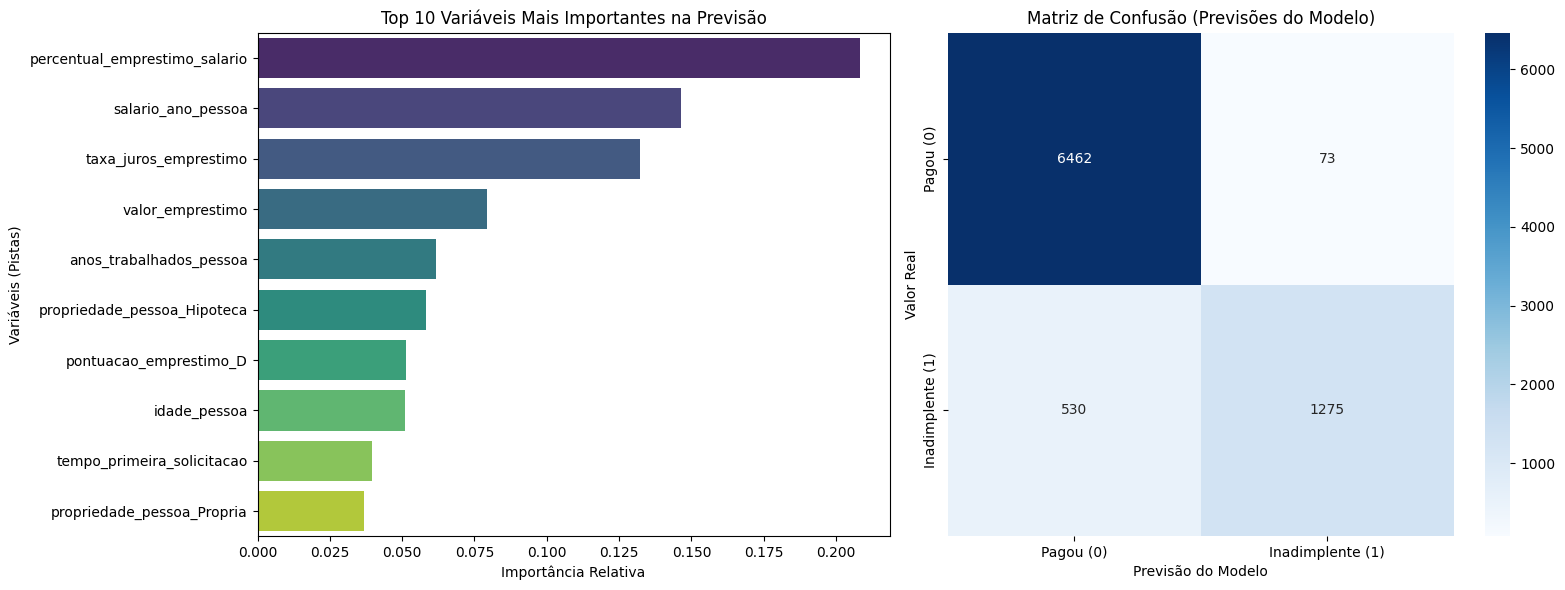

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configurar área de plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de Importância das Variáveis (Top 10)
importances = modelo.feature_importances_
indices = np.argsort(importances)[::-1]
colunas_ordenadas = X.columns[indices]
importances_ordenadas = importances[indices]

sns.barplot(x=importances_ordenadas[:10], y=colunas_ordenadas[:10], ax=axes[0], palette='viridis', hue=colunas_ordenadas[:10], legend=False)
axes[0].set_title('Top 10 Variáveis Mais Importantes na Previsão')
axes[0].set_xlabel('Importância Relativa')
axes[0].set_ylabel('Variáveis (Pistas)')

# 2. Matriz de Confusão em formato de mapa de calor
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Pagou (0)', 'Inadimplente (1)'],
            yticklabels=['Pagou (0)', 'Inadimplente (1)'])
axes[1].set_title('Matriz de Confusão (Previsões do Modelo)')
axes[1].set_xlabel('Previsão do Modelo')
axes[1].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

```markdown
## 📝 Entregáveis para Apresentação

Aqui está a síntese dos resultados estruturada exatamente conforme os requisitos para a sua apresentação:

### 1. Qual o Dataset?
* **Nome:** Base de Análise de Risco (Projeto Alura Cash).
* **Origem:** Challenge de Data Science da Alura.
* **Descrição:** Dados cadastrais e financeiros de clientes solicitantes de empréstimos, contendo informações como idade, salário anual, valor solicitado, taxa de juros, histórico de inadimplência, propriedade do imóvel, tempo de trabalho, entre outros.
* **Tamanho original:** 34.485 linhas e 15 colunas.

### 2. Análise Exploratória
* **Distribuição do Alvo:** A base é desbalanceada. Dos 34.485 registros originais, **27.036 (78,4%)** são clientes que pagaram (classe 0) e **7.449 (21,6%)** são inadimplentes (classe 1).
* **Dados Faltantes:** Identificou-se a presença de valores nulos (por exemplo, na taxa de juros), que foram tratados na etapa seguinte.
* **Principais Variáveis:** Através do gráfico de importância do modelo, identificamos que as variáveis mais determinantes para prever o risco são:
  1. A taxa de juros do empréstimo (`taxa_juros_emprestimo`)
  2. O percentual do empréstimo em relação à renda do cliente
  3. O salário anual do cliente (`salario_ano_pessoa`)

### 3. Pré-Processamento
Para garantir que o modelo de Machine Learning recebesse os dados de forma correta e sem viés, realizamos os seguintes passos:
1. **Tratamento de Valores Vazios:** Aplicação do método `.dropna()`, reduzindo a base consistente para **33.360 linhas**.
2. **Remoção de Identificadores:** Exclusão de colunas irrelevantes para a predição (como colunas que começam com `id_`).
3. **Codificação de Variáveis Categóricas:** Transformação de variáveis de texto (ex: tipo de propriedade, intenção do empréstimo) em colunas binárias numéricas utilizando a técnica de **One-Hot Encoding** (gerando 22 colunas finais).
4. **Divisão de Treino e Teste:** Separação de 75% dos dados para treino e 25% para teste, utilizando **estratificação** para manter a mesma proporção de inadimplentes em ambas as bases.

### 4. O que querem prever?
* **Alvo (Target):** `status_inadimplencia`
* **Objetivo:** Prever se um novo cliente que solicitou um empréstimo vai ficar inadimplente (classe `1`) ou se vai pagar o empréstimo em dia (classe `0`).

### 5. Qual o modelo escolhido?
* **Modelo:** **Random Forest Classifier (Floresta Aleatória)**.
* **Justificativa:** É um modelo ensemble baseado em múltiplas árvores de decisão. Foi escolhido por lidar extremamente bem com variáveis categóricas codificadas, ser robusto contra overfitting e permitir extrair facilmente a importância de cada característica (feature importance).

### 6. Qual foi a métrica de avaliação do Modelo?
Analisamos o desempenho do modelo na base de teste (8.340 clientes) sob as seguintes métricas:

* **Acurácia Geral:** **93%** (indica o acerto geral do modelo).
* **Precisão (Precision):**
  * Para quem paga (**0**): **92%**
  * Para inadimplentes (**1**): **95%** (Quando o modelo diz que o cliente vai ficar inadimplente, ele acerta em 95% das vezes).
* **Recall (Sensibilidade):**
  * Para quem paga (**0**): **99%**
  * Para inadimplentes (**1**): **71%** (O modelo consegue identificar de forma antecipada 71% de todas as pessoas que de fato ficariam inadimplentes).
* **F1-Score:** **0,81** para a classe de inadimplentes, mostrando um excelente equilíbrio entre precisão e recall para o cenário de risco de crédito.
```